# 19 人工神经网络

> **模块**：神经网络 ｜ **数据**：`midge.csv`、`pressure.csv` ｜ **依赖**：numpy、matplotlib、scikit-learn

- Machine Learning for Beginners: An Introduction to Neural Networks A simple explanation of how they work and how to implement one from scratch in Python.
-----
机器学习入门：神经网络简介 简单解释神经网络的工作原理，以及如何用 Python 从头开始实现一个神经网络。
https://victorzhou.com/blog/intro-to-neural-networks/


## 1. 问题背景

人工神经网络(Artificial Neural Network, ANN)是由大量简单的基本元件——神经元，相互连接，通过模拟人的大脑神经处理信息的方式，进行信息并行处理以及自学习能力。

人工神经网络已在模式识别、预测和控制系统等领域得到广泛的应用，它能够用来解决常规计算难以解决的问题。


## 2. 学习目标

- 了解人工神经网络构成和常用激活函数
- 掌握感知器模型的构建和预测


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现


In [ ]:
import numpy as np, matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def deriv_sigmoid(x):
    s = sigmoid(x)
    return s * (1 - s)

def mse_loss(y_true, y_pred):
    return ((y_true - y_pred) ** 2).mean()

class OurNeuralNetwork:
    """2输入 → 2隐藏 → 1输出 的神经网络"""
    def __init__(self):
        # 权重和偏置改用矩阵/向量存储
        self.W1 = np.random.randn(2, 2)   # 隐藏层权重 (2输入→2神经元)
        self.b1 = np.random.randn(2)      # 隐藏层偏置
        self.W2 = np.random.randn(1, 2)   # 输出层权重 (2隐藏→1输出)
        self.b2 = np.random.randn(1)      # 输出层偏置

    def feedforward(self, x):
        """前向传播，返回输出值及中间量（用于反向传播）"""
        z1 = x @ self.W1.T + self.b1      # 隐藏层线性输出
        a1 = sigmoid(z1)                  # 隐藏层激活值
        z2 = a1 @ self.W2.T + self.b2     # 输出层线性输出
        a2 = sigmoid(z2)                  # 输出层激活值
        return a2[0], a1, z1, z2[0]       # 返回标量输出、隐藏激活、线性值

    def train(self, data, all_y_trues):
        learn_rate = 0.1
        epochs = 1000
        loss_history = []

        for epoch in range(epochs):
            for x, y_true in zip(data, all_y_trues):
                # 前向传播
                y_pred, h, z1, z2 = self.feedforward(x)

                # 损失对输出的梯度
                dL_do = -2 * (y_true - y_pred)
                # 输出层的局部梯度（乘上sigmoid导数）
                d_out = dL_do * deriv_sigmoid(z2)

                # 输出层权重与偏置的梯度
                dW2 = d_out * h                 # (2,)
                db2 = d_out

                # 隐藏层梯度
                d_h = d_out * self.W2[0]        # (2,)
                d_hidden = d_h * deriv_sigmoid(z1)  # (2,)
                dW1 = np.outer(d_hidden, x)     # (2,2)
                db1 = d_hidden

                # 参数更新
                self.W2 -= learn_rate * dW2.reshape(1, 2)
                self.b2 -= learn_rate * db2
                self.W1 -= learn_rate * dW1
                self.b1 -= learn_rate * db1

            # 每10轮计算并记录损失
            if epoch % 10 == 0:
                preds = np.array([self.feedforward(x)[0] for x in data])
                loss = mse_loss(all_y_trues, preds)
                loss_history.append(loss)
                print(f"Epoch {epoch} loss: {loss:.3f}")

        # 绘制损失曲线
        plt.plot(range(0, epochs, 10), loss_history)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Loss per Epoch')
        plt.show()

# 数据集
data = np.array([
    [-2, -1],
    [25, 6],
    [17, 4],
    [-15, -6],
])
all_y_trues = np.array([1, 0, 0, 1])

# 训练
network = OurNeuralNetwork()
network.train(data, all_y_trues)

## 5. 导读

初学人工智能不久，碰上了人工神经网（ANN），开始学的时候很懵，一大堆理论、公式、推导…作为一名小白，还是很痛苦的，不过经过摸索，大概了 解了什么是ANN，公式的推导以及一些其他问题，下面我就总结下自己的理解，一方面作为自己的笔记，日后方便巩固；另一方面，也可以分享给其他有意者。

### 5.1 人工神经网络概述

#### 5.1.1 人工神经网络构成

下图为人工神经网络（ANN）的基本单元的神经元模型。

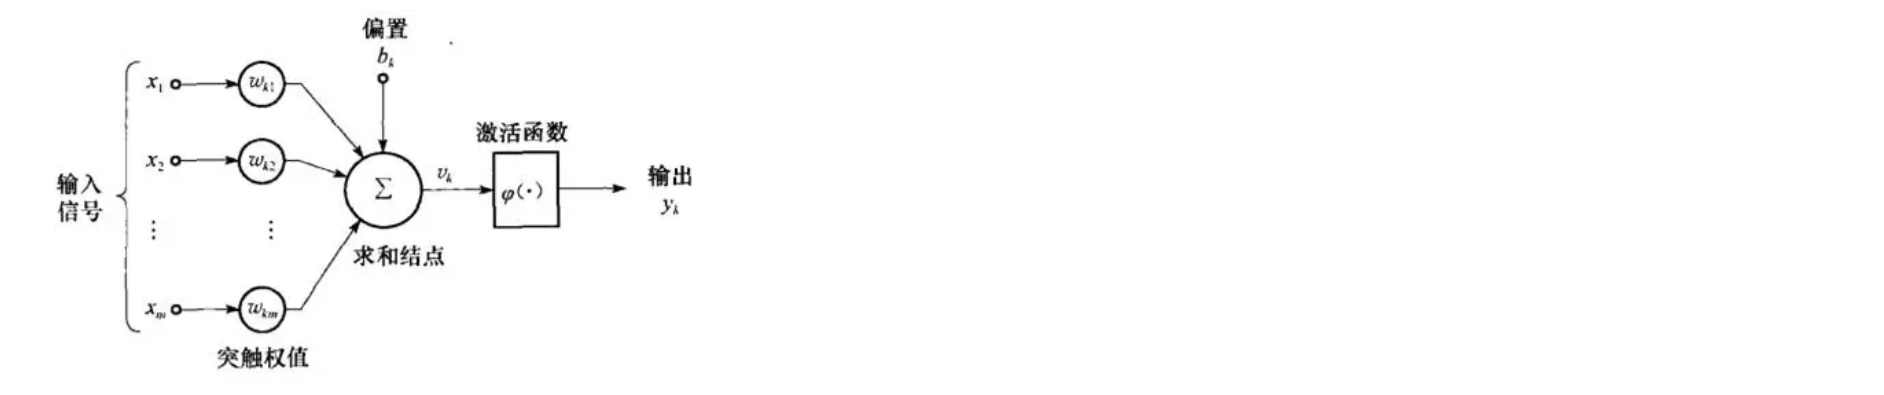

人工神经网络，它有三个基本要素：
1. 一组连接（对应于生物神经元的突触），连接强度由各连接上的权值表示，权值为正表示激活，为负表示抑制。
2. 一个求和单元，用于求取各输入信号的加权和（线性组合）。
3. 一个非线性激活函数，起非线性映射作用并将神经元输出幅度限制在一定范围内（一般限制在 (0,1) 或 (-1,1) 之间）。

#### 5.1.2 常用激活函数

- （1）阈值型函数（一般只用在简单分类的神经元模型中）

$$f(x) =
\begin{cases}
0, & x < 0 \\
1, & x ≥ 0
\end{cases}$$

- （2）线性型函数（一般只用在输入神经元和输出神经元）

$$f(x) = ax + b$$

- （3）S型函数/sigmoid函数（常用于隐藏层神经元）

$$f(x) = \frac{1}{1 + e^{-x}}$$

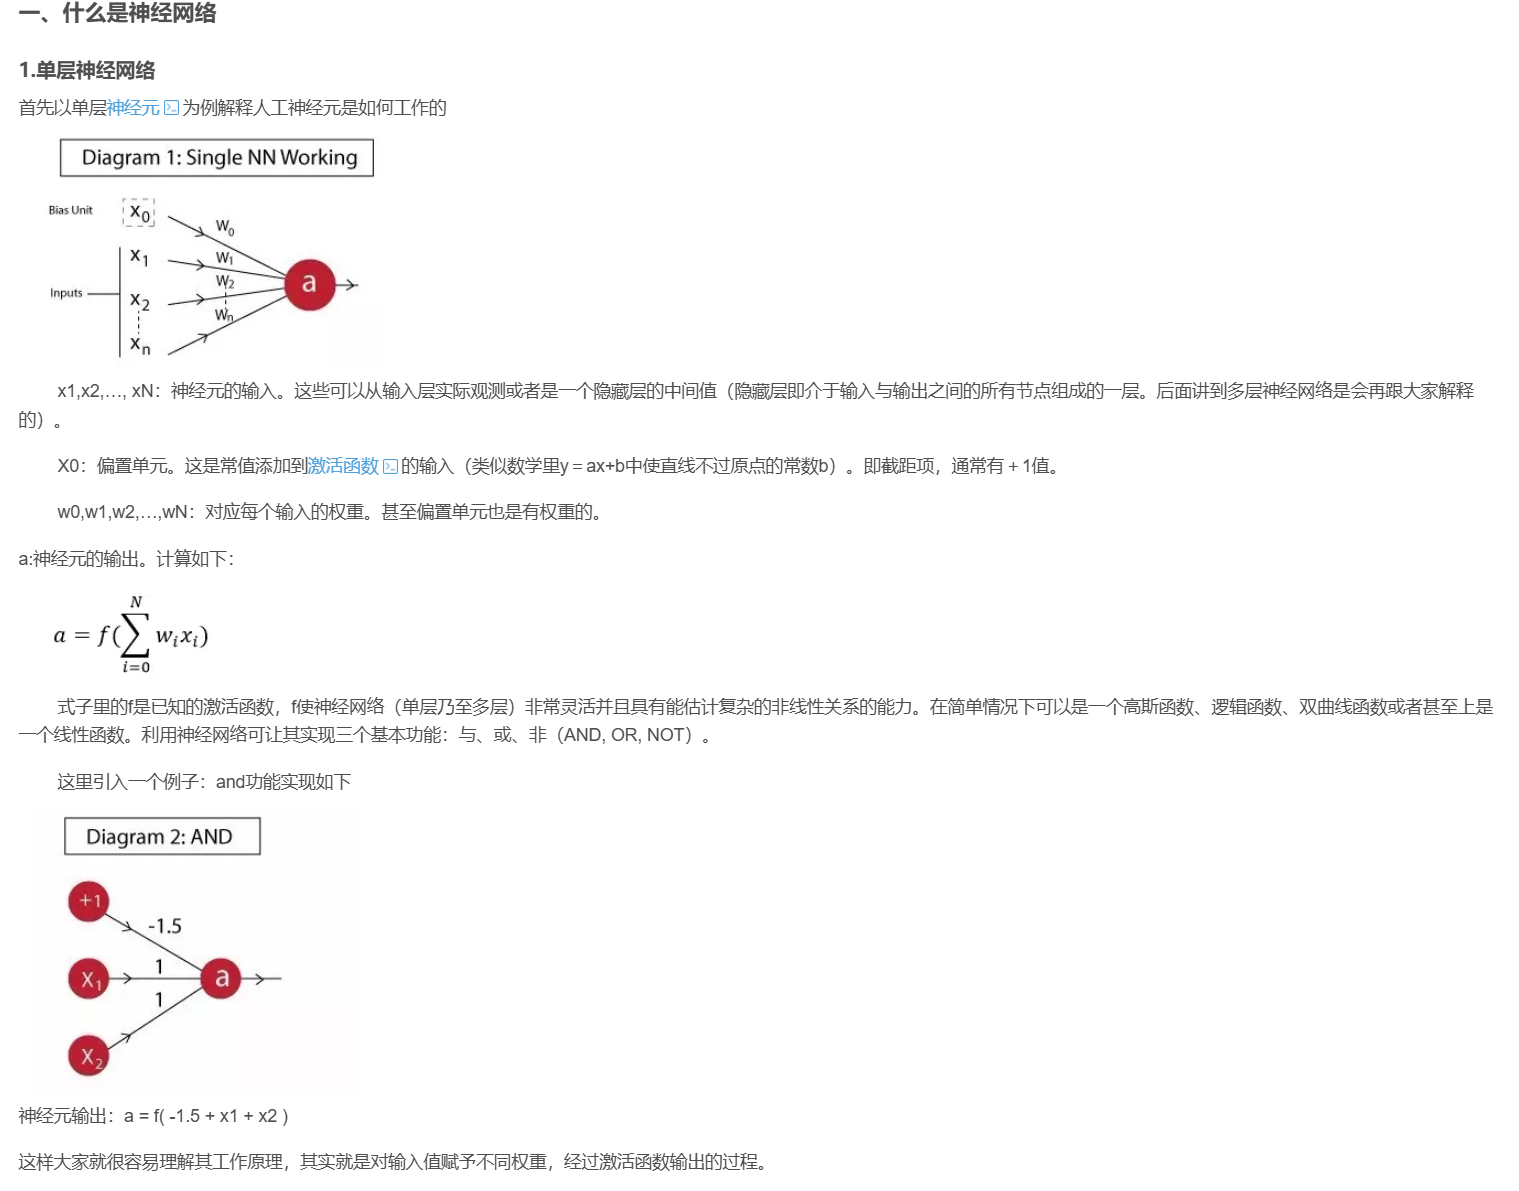

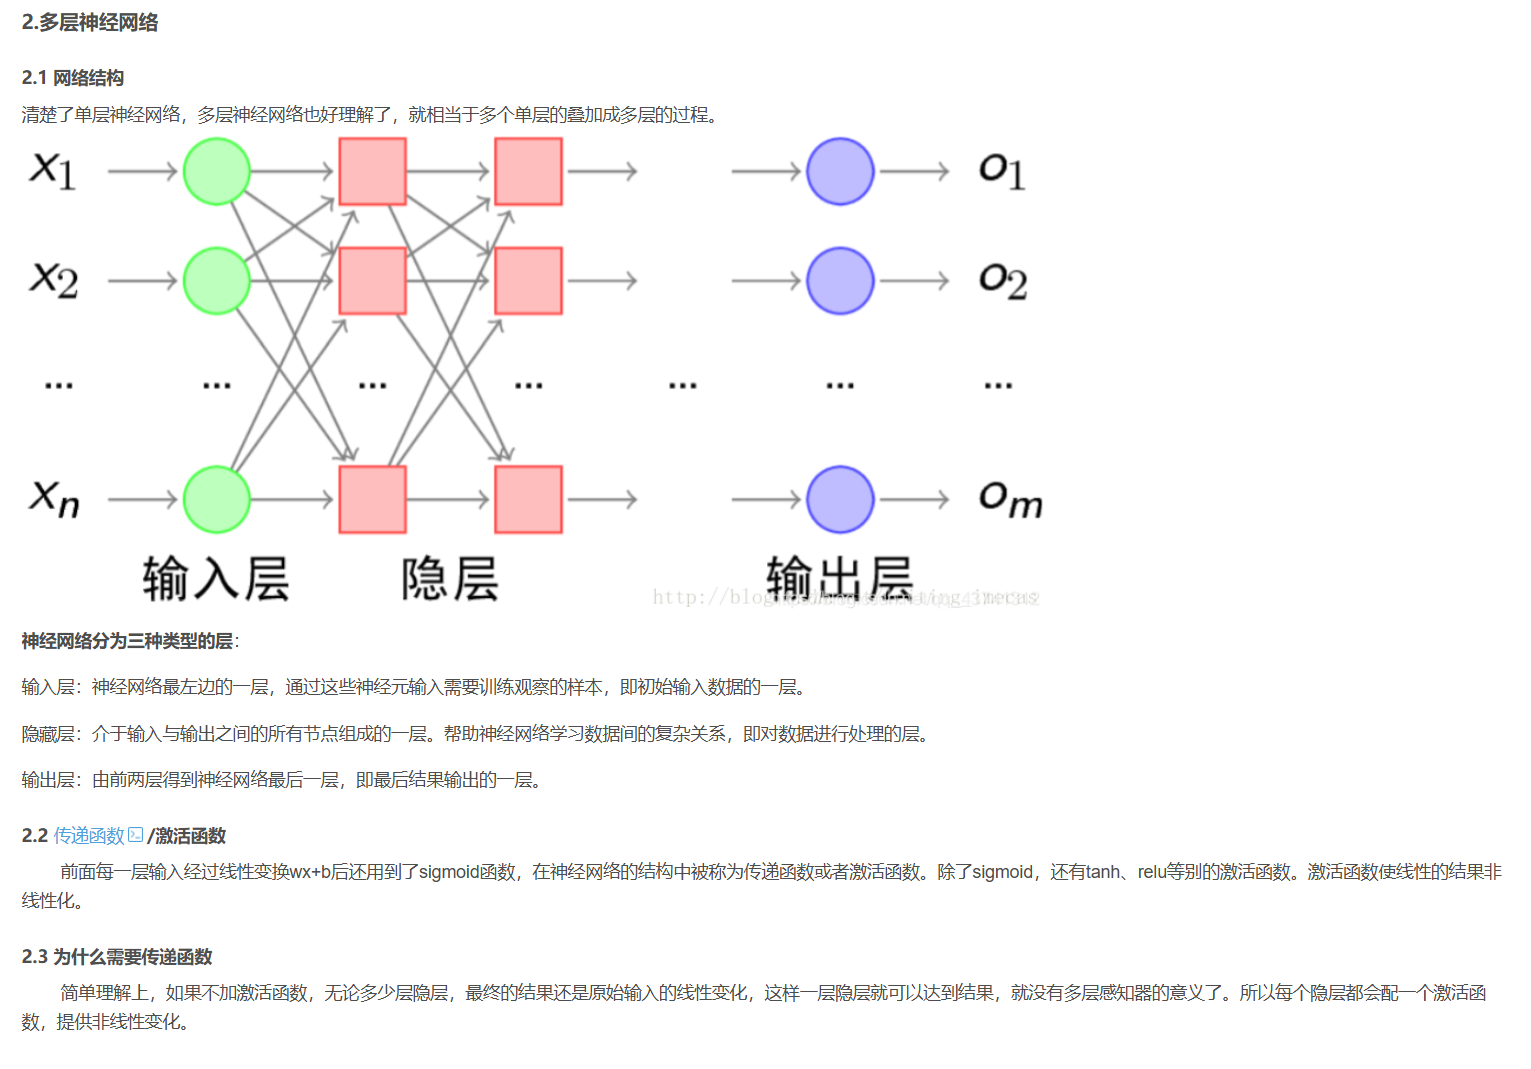

### 5.2 神经网络的基本模型

#### 5.2.1 感知器模型

感知器是最早的人工神经网络。单层感知器是一个具有一层神经元、采用阈值激活函数的前馈式人工神经网络。

感知机（perceptron）是二类分类的线性分类模型，其输入为实例的特征向量，输出为实例的类别。感知机对应于输入空间（特征空间）中将实例划分为正负两类的分离超平面。感知机是一种**线性分类模型**。

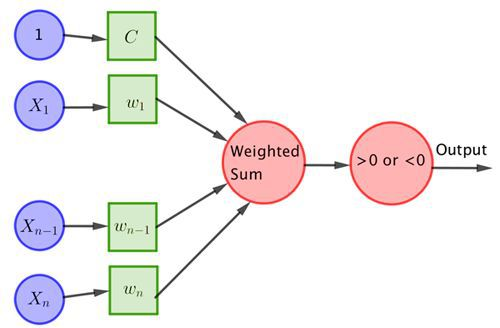

**例1**.朦虫分类

（1989年国际大学生数学建模竞赛A题：蠓虫分类）蠓虫是一种昆虫，分为很多类型，其中有一种名为Af，是能传播花粉的益虫；另一种名为Apf，是会传播疾病的害虫。这两种类型的蠓虫在形态上十分相似，很难区别。现测得9只Af和6只Apf蠓虫的触角长度和翅膀长度数据。

Af：(1.24,1.72)，(1.36,1.74)，(1.38,1.64)，(1.38,1.82)，(1.38,1.90)，(1.40,1.70)，(1.48,1.82)，(1.54,1.82)，(1.56,2.08)；

Apf：(1.14,1.78)，(1.18,1.96)，(1.20,1.86)，(1.26,2.00)，(1.28,2.00)，(1.30,1.96)。

试判别(1.24,1.80)这只蠓虫属于哪一类。

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron
plt.rc('font', family='SimHei') 
plt.rc('axes', unicode_minus=False)
data = pd.read_csv('../data/midge.csv') 
pd.set_option('display.max_columns', None) 
x = data.iloc[:, :-1].values
y = data.iloc[:, -1].values 
data.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
触角长度,1.24,1.36,1.38,1.38,1.38,1.4,1.48,1.54,1.56,1.14,1.18,1.20,1.26,1.28,1.30
翅膀长度,1.72,1.74,1.64,1.82,1.90,1.7,1.82,1.82,2.08,1.78,1.96,1.86,2.00,2.00,1.96
target,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00


感知机模型创建

```python
sklearn.linear_model.Perceptron(penalty=None, alpha=0.0001, fit_intercept=True, max_iter=None, tol=None, shuffle=True, verbose=0, eta0=1.0, n_jobs=None, random_state=0, early_stopping=False, validation_fraction=0.1, n_iter_no_change=5, class_weight=None, warm_start=False, n_iter=None)
```

- `penalty`：惩罚项，避免模型过拟合风险。默认=`None`，即不加惩罚项，`'l2'`（L2正则）或`'l1'`（L1正则）或`'elasticnet'`（混合正则）。
- `max_iter`：最大迭代次数。
- `tol`：迭代停止标准。当`loss - pre_loss < tol`时，迭代停止。

系数和截距项为：a = [-1.42  1.02]，b = [0.]
训练数据正确率 1.0
预测值为： [1.]


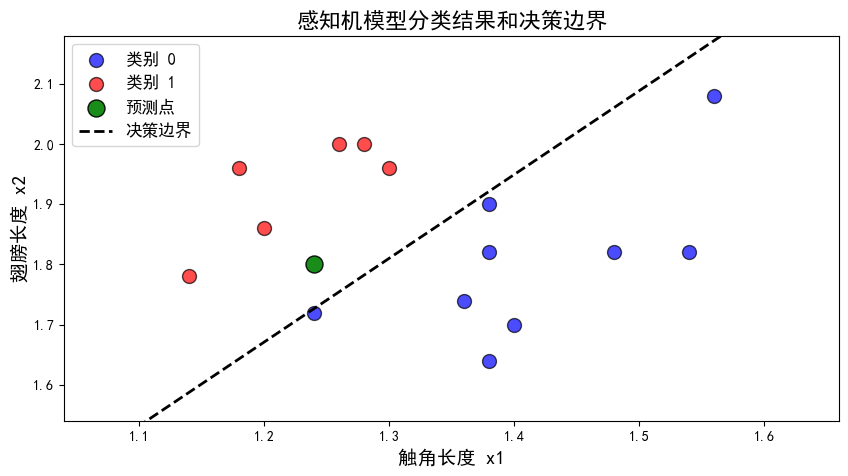

In [6]:
md = Perceptron(tol=1e-3)
md.fit(x, y)

# 输出系数和常数项
a = md.coef_[0]
b = md.intercept_
print('系数和截距项为：a = {}，b = {}'.format(a, b))
print('训练数据正确率', md.score(x, y))

# 修正2：预测时同样使用数组，消除警告（因训练时 x 已是数组）
print("预测值为：", md.predict(np.array([[1.24, 1.80]])))

# 绘图
plt.figure(figsize=(10, 5))
# 分类绘制散点图
plt.scatter(x[:9, 0], x[:9, 1], label='类别 0', color='blue', s=100,
            edgecolors='black', alpha=0.7)
plt.scatter(x[9:, 0], x[9:, 1], label='类别 1', color='red', s=100,
            edgecolors='black', alpha=0.7)
plt.scatter(1.24, 1.80, label='预测点', color='green', s=150,
            edgecolors='black', alpha=0.9, marker='o')   # 换成圆形，黑色边缘可见

# 绘制超平面
x1 = np.linspace(x[:, 0].min() - 0.1, x[:, 0].max() + 0.1, 50)
plt.plot(x1, (-a[0] * x1 - b) / a[1], label='决策边界', color='black',
         linestyle='--', linewidth=2)

plt.title('感知机模型分类结果和决策边界', fontsize=16)
plt.xlabel('触角长度 x1', fontsize=14)
plt.ylabel('翅膀长度 x2', fontsize=14)
plt.xlim(x[:, 0].min() - 0.1, x[:, 0].max() + 0.1)
plt.ylim(x[:, 1].min() - 0.1, x[:, 1].max() + 0.1)
plt.legend(fontsize=12)
plt.show()

#### 5.2.2 BP 神经网络模型

BP算法是一种神经网络学习算法，由输入层、中间层和输出层组成。

中间层可扩展为多层，相邻层之间各神经元进行全连接，而每层各神经元之间无连接。

网络安装有监督的方式进行学习，当数据输入后，各神经元获得网络的输入响应产生连接权值。然后按减少希望输出与实际输出的误差的方向（梯度方向），从输出层经各中间层逐层修正各连接权值，回到输入层。此过程反复交替进行，直至网络的全局误差趋向给定的极小值，即完成学习过程。

**BP神经网络的基本思想：信号的正向传播，误差的反向传播。**

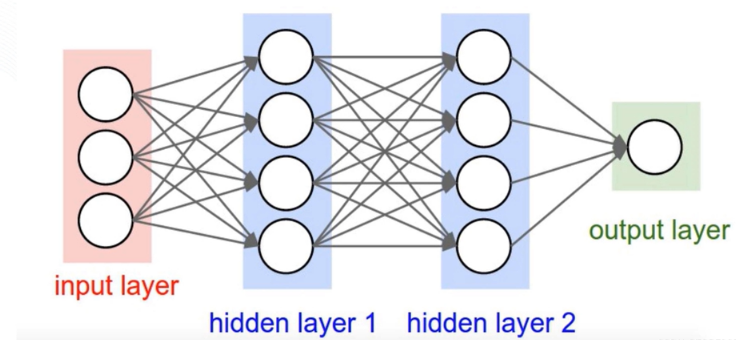

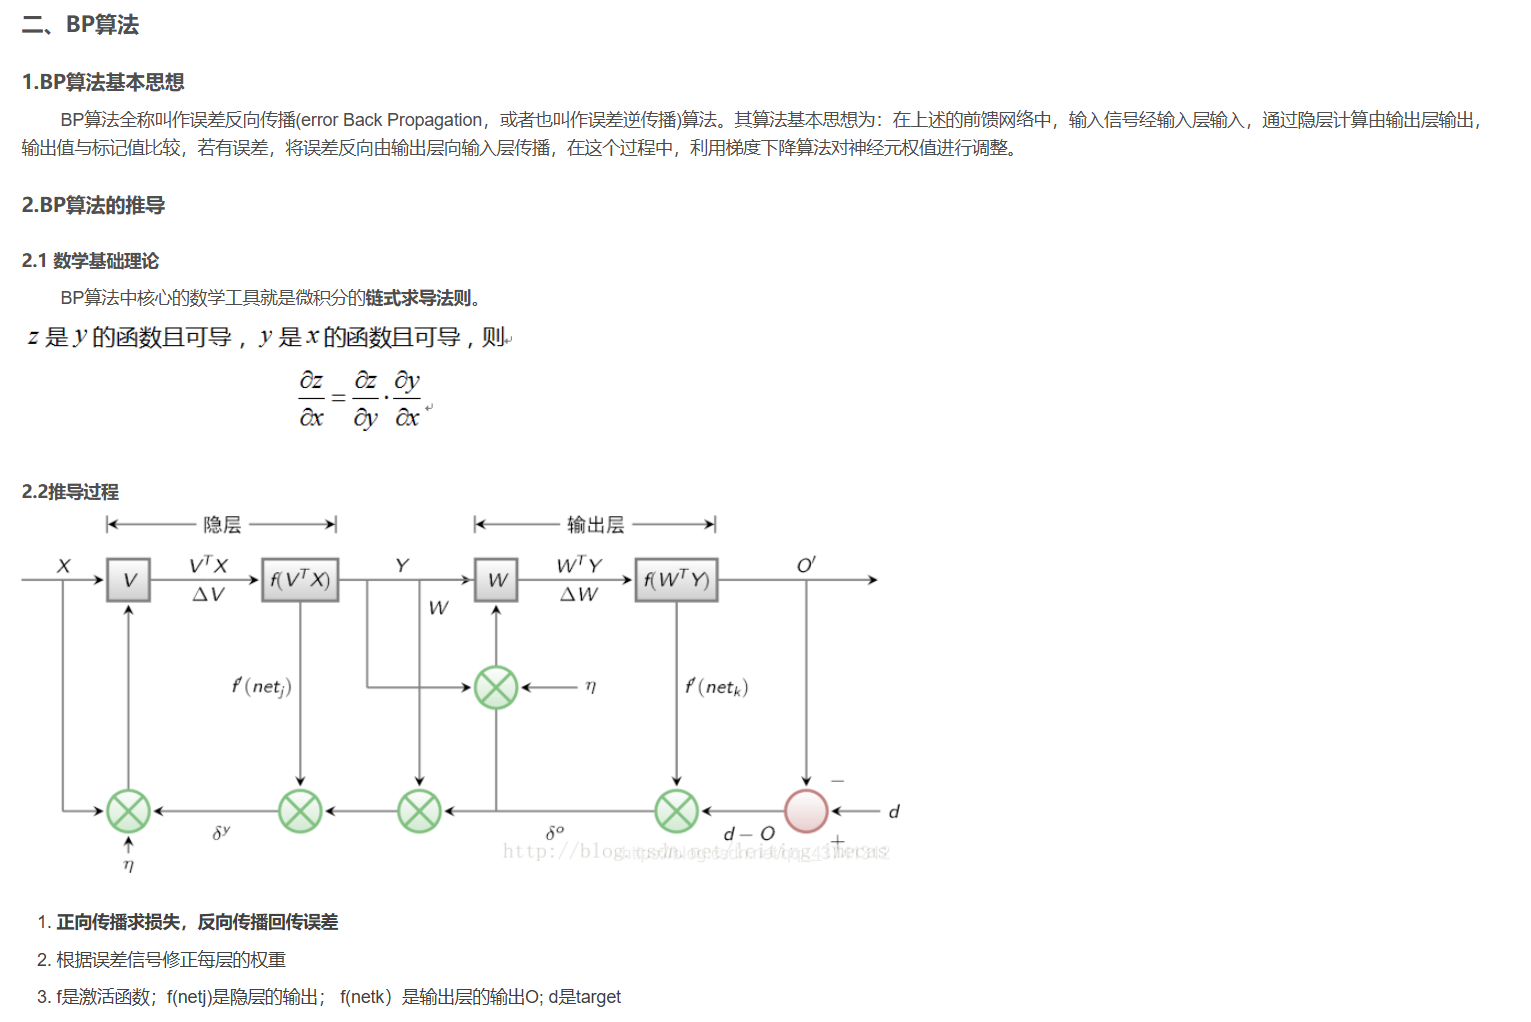

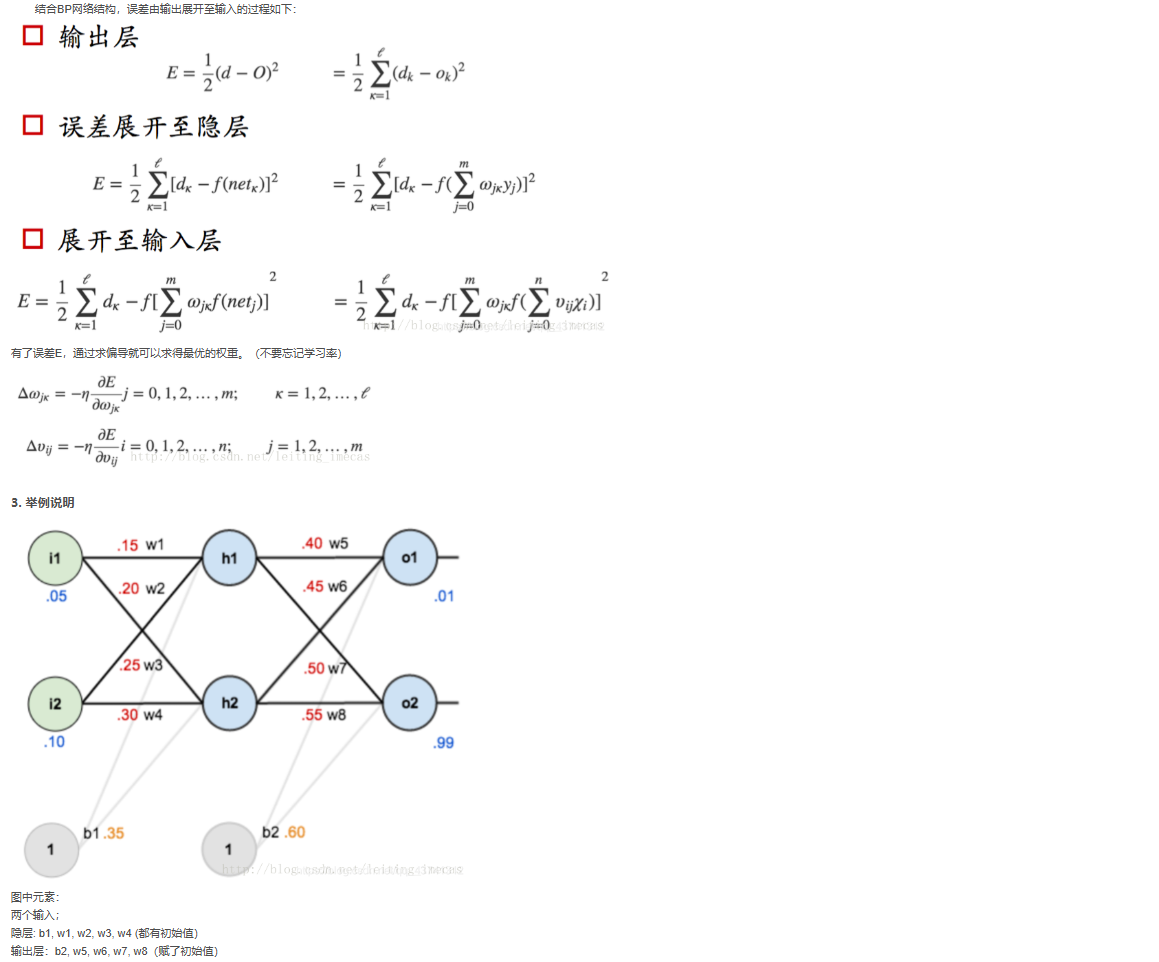

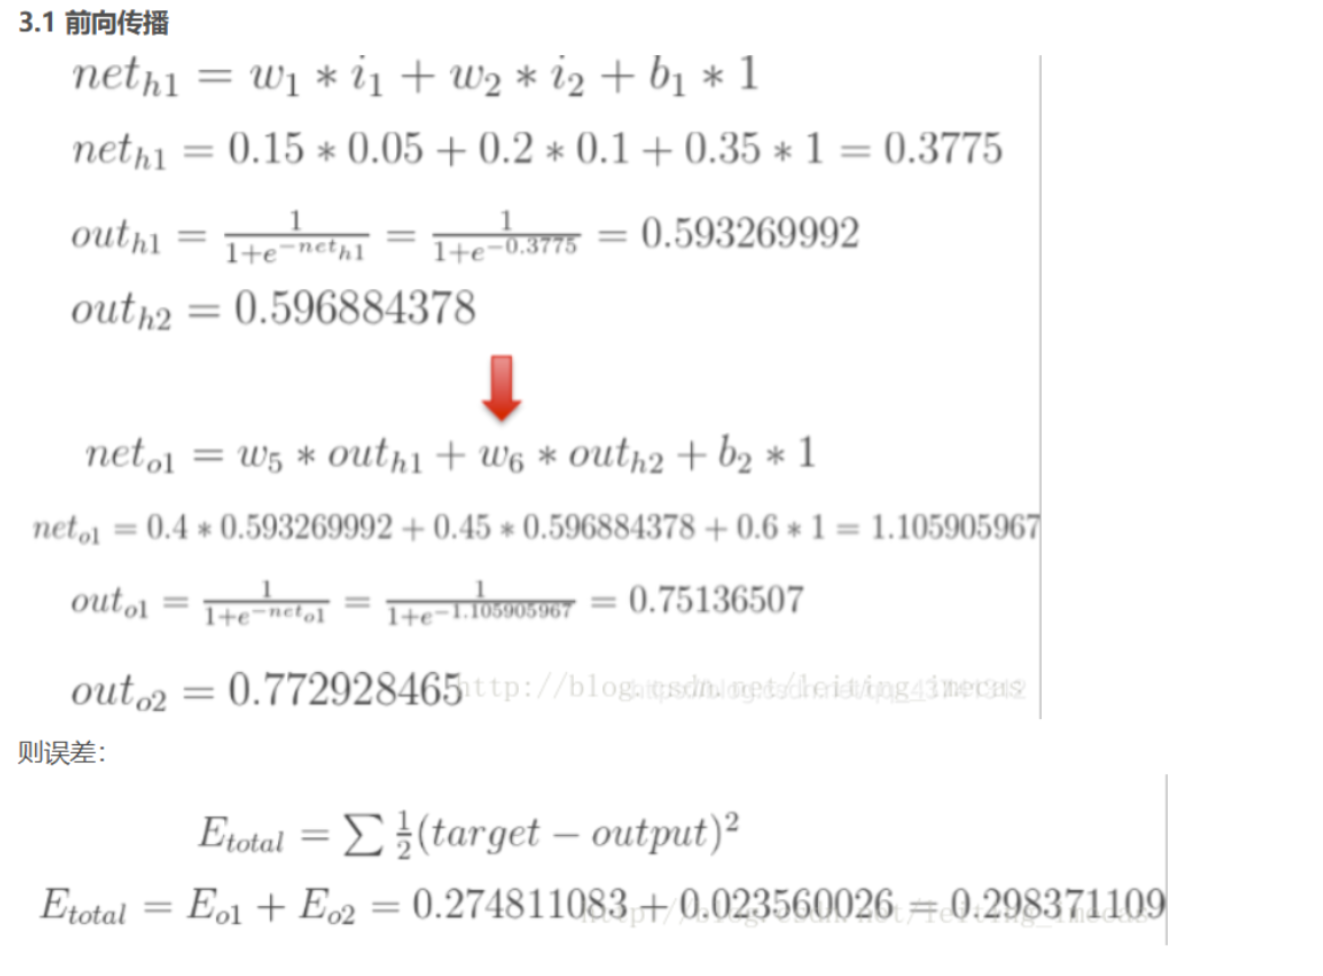

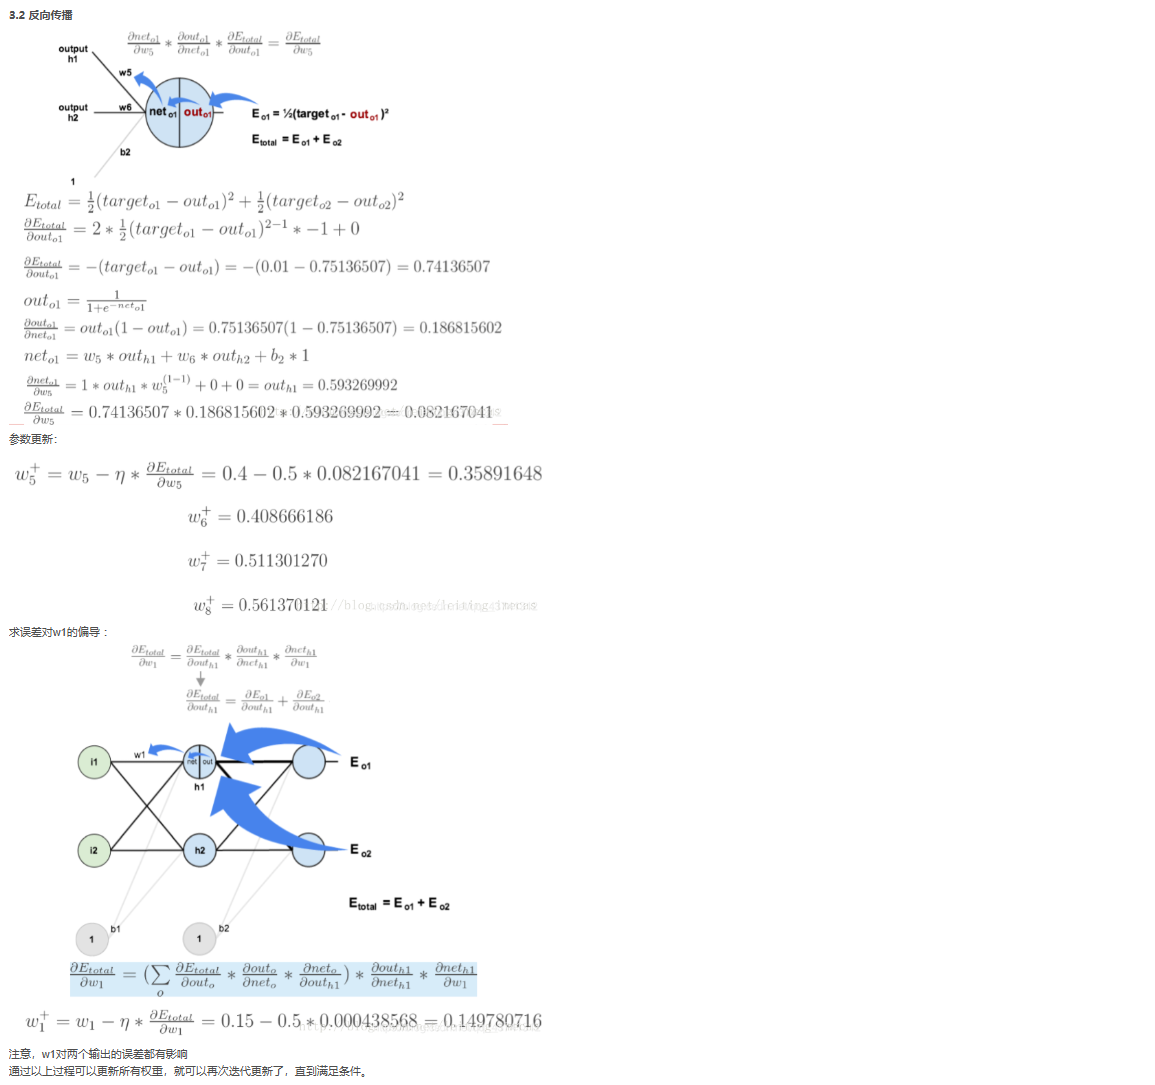

示例：
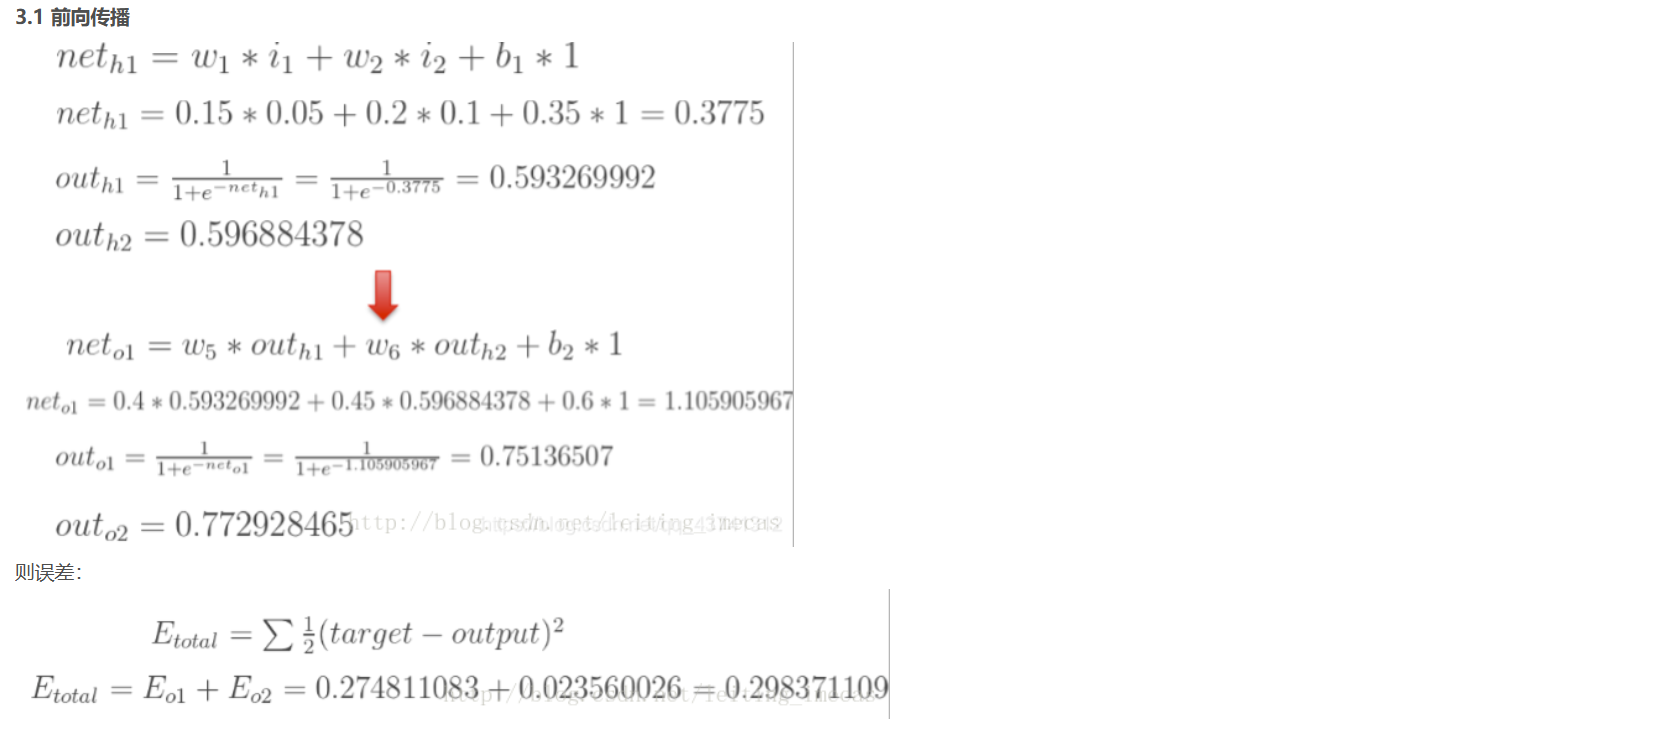
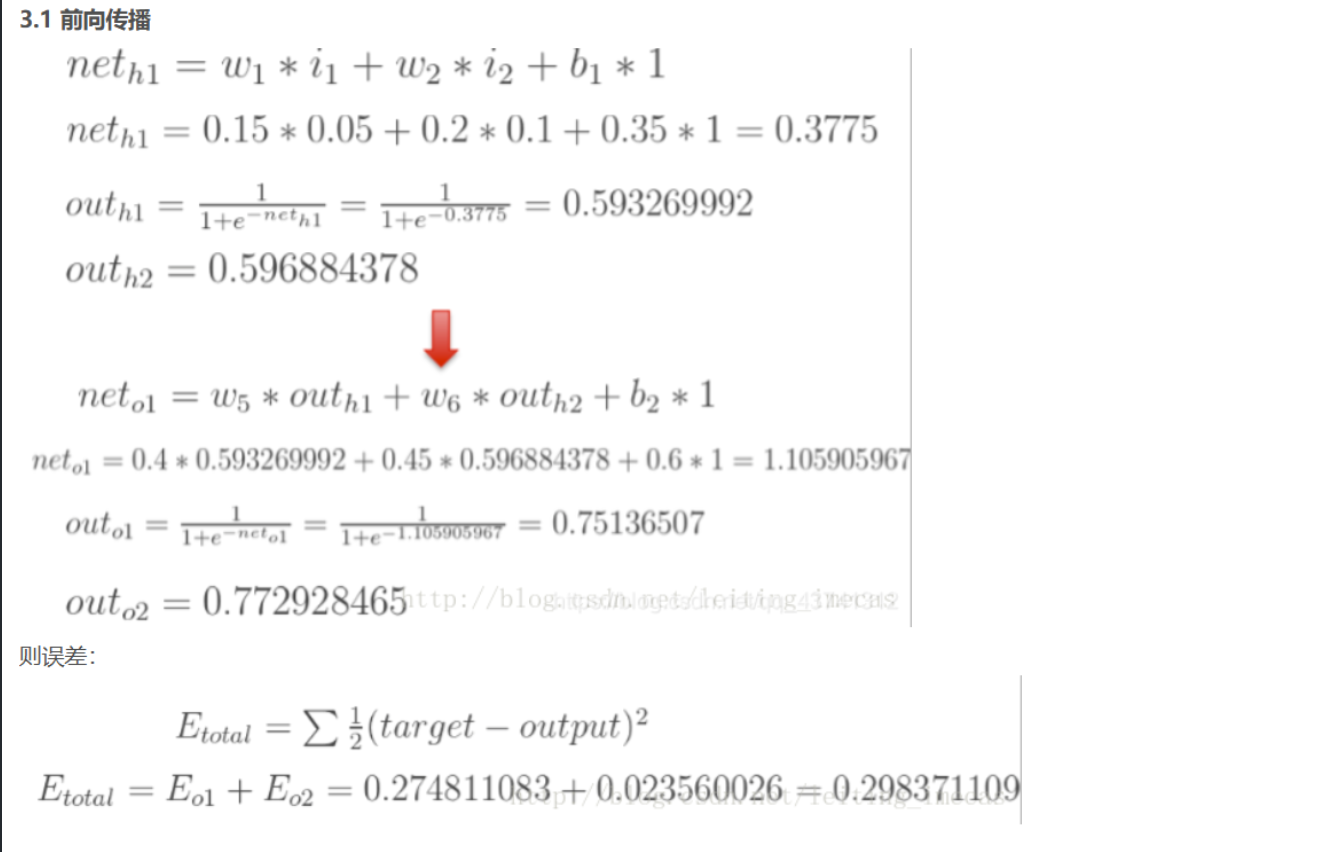

Iterations: 10000, final loss: 3.510854812251261e-05, output: [0.01591419 0.98406371]


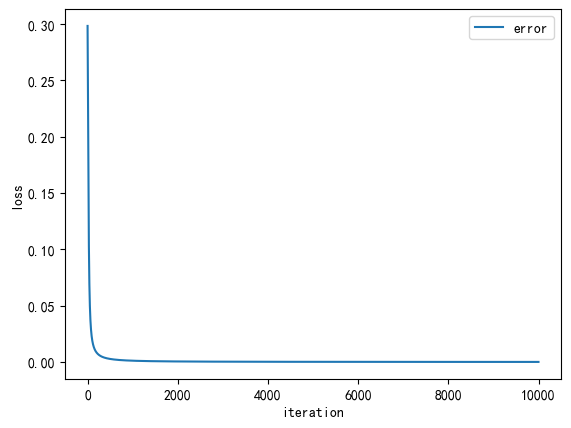

In [10]:
import numpy as np
import matplotlib.pyplot as plt

# 参数初始化
a = np.array([0.05, 0.1])
W1 = np.array([[0.15, 0.25], [0.2, 0.3]])
W2 = np.array([[0.4, 0.5], [0.45, 0.55]])
b1, b2 = 0.35, 0.6
target = np.array([0.01, 0.99])
lr = 0.5

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

errors = []
for i in range(10000):
    # 前向传播
    h = sigmoid(np.dot(a, W1) + b1)
    y = sigmoid(np.dot(h, W2) + b2)

    # 误差计算
    loss = 0.5 * np.sum((target - y) ** 2)
    errors.append(loss)
    if loss < 1e-7:
        break

    # 反向传播
    delta2 = -(target - y) * y * (1 - y)               # 输出层误差项
    delta1 = np.dot(W2, delta2) * h * (1 - h)          # 隐藏层误差项

    # 梯度更新（权重，偏置未更新，与原代码一致）
    W2 -= lr * np.outer(h, delta2)
    W1 -= lr * np.outer(a, delta1)

print(f"Iterations: {i+1}, final loss: {loss}, output: {y}")
plt.plot(errors)
plt.xlabel('iteration')
plt.ylabel('loss')
plt.legend(['error'])
plt.show()

##### 5.2.2.1 基于 BP 算法的多层感知器模型实现

**例2**.在人的身高相等的情况下，血压的收缩压与体重有关，收集了13个男子的数据如下表，并将下表数据（含表头，不含序号列）保存至pressure.csv文件中。
试确定模型,并试预测一体重为81千克，年龄为40岁男子的收缩压。

> *原稿配图未随 notebook 保存，此处暂缺。*


In [14]:
df = pd.read_csv('../data/pressure.csv') 
# 按照blood列数据升序排序
df = df.sort_values(by ='blood' )
# 提取自变量与因变量
X = df.loc[:,df.columns != 'blood']
Y = df['blood']
df = df.T

多层感知机回归器模型创建：
```python
sklearn.neural_network.MLPRegressor(
    hidden_layer_sizes=(100,),
    activation='relu',
    solver='adam',
    alpha=0.0001,
    batch_size='auto',
    learning_rate='constant',
    learning_rate_init=0.001,
    power_t=0.5,
    max_iter=200,
    shuffle=True,
    random_state=None,
    tol=0.0001,
    verbose=False,
    warm_start=False,
    momentum=0.9,
    nesterovs_momentum=True,
    early_stopping=False,
    validation_fraction=0.1,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-08
)

```
- $hidden_layer_sizes$：隐藏层神经元数，例如$hidden_layer_sizes=(50, 50)$，表示有两层隐藏层，第一层隐藏层有50个神经元，第二层也有50个神经元。
- $activation$：激活函数。
- $solver$：权重优化的求解，对小数据集来说，$lbfgs$收敛更快效果也更好。
- $tol$：迭代停止的标准。$loss-pre-loss<tol$的时候，就会停止迭代。

训练集MSE: 14.388495442456406
预测收缩压: [122.59847798 121.24792935 121.0231704  122.98181729 130.87985965
 127.89449207 125.67897116 127.8747346  133.16086996 128.63836428
 139.92487101 141.4323729  148.23588889]
体重81kg，年龄40岁男子预测收缩压: 127.13086238870125


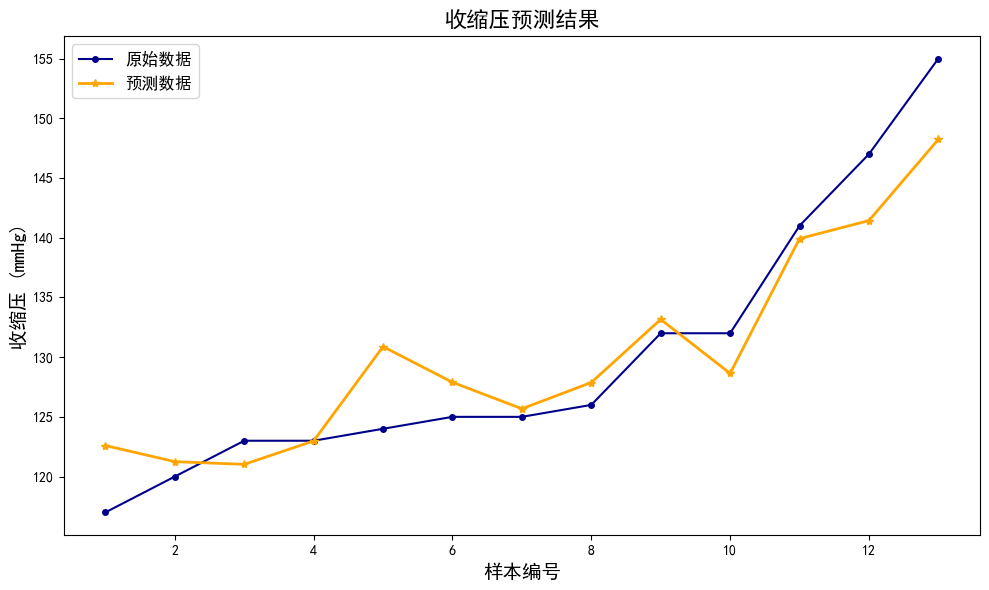

In [18]:
import numpy as np, matplotlib.pyplot as plt, warnings
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error
warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")  # 忽略特征名警告

model = MLPRegressor(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(10,), random_state=42).fit(X, Y)
train_pred, test_pred = model.predict(X), model.predict([[81, 40]])
print(f'训练集MSE: {mean_squared_error(Y, train_pred)}\n预测收缩压: {train_pred}\n体重81kg，年龄40岁男子预测收缩压: {test_pred[0]}')
plt.figure(figsize=(10, 6))
plt.plot(np.arange(len(Y))+1, Y, 'o-', label='原始数据', color='darkblue', ms=4)
plt.plot(np.arange(len(Y))+1, train_pred, '-*', label='预测数据', color='orange', lw=2, ms=6)
plt.legend(fontsize=12); plt.title("收缩压预测结果", fontsize=16); plt.xlabel("样本编号", fontsize=14); plt.ylabel("收缩压 (mmHg)", fontsize=14)
plt.tight_layout(); plt.show()

**BP神经网络的优缺点**

1.BP神经网络的优点：

- 非线性映射能力
- 泛化能力
- 容错能力，允许输入样本中带有较大误差甚至个别错误。反应正确规律的知识来自全体样本，个别样本中的误差不能左右对权矩阵的调整

2.BP神经网络的缺陷：

- 需要的参数过多，而且参数的选择没有有效的方法。确定一个BP神经网络需要知道：网络的层数、每一层神经元的个数和权值。权值可以通过学习得到，如果，隐层神经元数量太多会引起过学习，如果隐层神经元个数太少会引起欠学习。此外学习率的选择也是需要考虑。目前来说，对于参数的确定缺少一个简单有效的方法，所以导致算法很不稳定；
- 属于监督学习，对于样本有较大依赖性，网络学习的逼近和推广能力与样本有很大关系，如果样本集合代表性差，样本矛盾多，存在冗余样本，网络就很难达到预期的性能；
- 由于权值是随机给定的，所以BP神经网络具有不可重现性；

#### 5.2.3 RBF 神经网络模型

径向基函数神经网络（Radial Basis Function Neural Network，RBF神经网络）是一类常用的三层前馈网络，既可用于函数逼近，也可用于模式分类。与其他类型的人工神经网络相比，RBF网络有生理学基础，结构简单，学习速度快，优良的逼近性能和泛化能力等特点。

BP神经网络与RBF神经网络模型区别
- 1）BP神经网络层次不做限制，RBF神经网络隐层仅有一层
- 2）BP神经网络激活函数使用S型函数，RBF神经网络激活函数使用径向基函数
- 3）BP神经网络是全局逼近网络(收敛速度慢)，RBF神经网络是局部逼近网络(收敛速度快)

**全局逼近：当神经网络中一个或者多个参数对任何一个输出都有一定程度上影响**

**局部逼近：当输入空间的某个局部区域只有少数几个连接权重影响输出**


### 5.3 BP 网络完整实现

> 来源：教材参考实现《数学建模算法与应用》15.7 节的练习稿（MIT，Zhanghan Wang），代码保持原样，仅按需改写数据路径并清空输出。

#### 1.BP神经网络
见 'MPLClassifier.ipynb'

#### 2.RBF神经网络

- RBF神经网络经过这样两层变化: $\left\{\begin{array}{l}R_i(X)=exp(-||X-C_i||^2/2\sigma_i^2),\qquad i=1,\cdots,m\\\hat{y}_k=\sum\limits_{i=1}^{m}\omega_{ik}R_i(X),\qquad k=1,\cdots,p\end{array}\right.$  
这样只有小部分靠近中心的隐藏层神经元被激活($R_i(X)$随着其中范数增大,指数减少)
- 确定基函数中心$C_i$. 一般采用K均值聚类法.
- 确定基函数宽度$\sigma_i$. 通常令它等于基函数中心与子样本集中样本模式之间的平均距离
- 确定权值$\omega_{ik}$. 采用最小均方误差测度.

In [ ]:
# RBF神经网络(based on tensorflow): https://github.com/shiluqiang/RBF_NN_tensorflow/blob/master/RBF_tensorflow.py
# 由于数据量小, 本人的不熟悉等原因, 预测结果并不理想.

import tensorflow as tf
import numpy as np
from matplotlib import pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
import pandas as pd
from sklearn import preprocessing

class RBF_NN():
    def __init__(self, hidden_nodes, input_data_trainX, input_data_trainY):
        self.hidden_nodes = hidden_nodes #隐含层节点数
        self.input_data_trainX = input_data_trainX #训练样本的特征
        self.input_data_trainY = input_data_trainY #训练样本的标签
    
    def fit(self):
        '''模型训练
        '''
        tf.compat.v1.disable_eager_execution()
        # 1.声明输入输出的占位符
        n = 19
        n_input = (self.input_data_trainX).shape[1]
        n_output = (self.input_data_trainY).shape[0]
        X = tf.compat.v1.placeholder('float', [None, n_input],name = 'X')
        Y = tf.compat.v1.placeholder('float', [None, 1],name = 'Y')
        
        # 2.参数设置
        ## RBF函数参数
        ### K-means求中心
        random_state = 170
        kms = KMeans(n_clusters=self.hidden_nodes, random_state=None)
        pred = kms.fit_predict(trainX)
        
        # c = tf.Variable(tf.random_normal(shape=(self.hidden_nodes, n_input)),name = 'c')
        # c = tf.concat((tf.cast(tf.Variable(kms.cluster_centers_), tf.float32), c), axis=0)
        c = tf.cast(tf.Variable(kms.cluster_centers_), tf.float32)
        delta = tf.Variable(tf.compat.v1.random_normal(shape=(1,self.hidden_nodes)), name='delta')
        ## 隐含层到输出层权重和偏置
        W = tf.Variable(tf.compat.v1.random_normal(shape=(self.hidden_nodes, 1)), name='W')
        b = tf.Variable(tf.compat.v1.random_normal(shape=(1, 1)), name='b')
        
        # 3.构造前向传播计算图
        ## 隐含层输出
        ### 特征样本与RBF均值的距离
        dist = tf.reduce_sum(tf.square(tf.subtract(tf.tile(X,[self.hidden_nodes, 1]),c)), axis=1)
        dist = tf.multiply(1.0,tf.transpose(dist))
        ### RBF方差的平方
        delta_2 = tf.square(delta)
        ### 隐含层输出
        RBF_OUT = tf.exp(tf.multiply(-1.0,tf.divide(dist,tf.multiply(2.0,delta_2))))
        ## 输出层输入
        output_in = tf.matmul(RBF_OUT, W) + b
        
        # 4.声明代价函数优化算法
        loss = tf.reduce_mean(tf.pow(Y - output_in,2)) #损失函数为均方误差
        train_op = tf.compat.v1.train.AdamOptimizer(0.1).minimize(loss) #优化算法为梯度下降法
    
        # 5.反向传播求参数
        trX = self.input_data_trainX[:n]
        trY = self.input_data_trainY[:n]
        
        with tf.compat.v1.Session() as sess:
            ## 初始化所有参数
            tf.compat.v1.global_variables_initializer().run()
            for epoch in range(200):
                for i in range(trX.shape[0]):
                    feed = {X:trX[i][:,None].T, Y:[[trY[i]]]}
                    sess.run(train_op,feed_dict=feed)
                if epoch % 20. == 0 :
                    total_loss = 0.0
                    for j in range(trX.shape[0]):
                        total_loss += sess.run(loss, feed_dict={X:trX[i][:,None].T, Y:[[trY[i]]]})
                    print('Loss function at step %d is %s'%(epoch, total_loss / trX.shape[0]))
                    
            print('Training complete!')

            W = W.eval()
            b = b.eval()
            c = c.eval()
            delta = delta.eval()
            pred_trX = np.mat(np.zeros((len(trX),n_output)))
            
            ## 训练准确率
            correct_tr = 0.0
            pred = []
            for i in range(self.input_data_trainX.shape[0]):
                pred_tr = sess.run(output_in, feed_dict={X:self.input_data_trainX[i][:,None].T})
                pred.append(pred_tr[0][0])
            df_columns = ['Input', 'Pred Out', 'Raw Out', 'Error', 'Relative Error']
            pred = np.array(pred)
            df = pd.DataFrame(np.c_[[x.__str__() for x in self.input_data_trainX],
                                    pred,
                                    self.input_data_trainY,
                                    np.subtract(pred, self.input_data_trainY),
                                    np.array(np.divide(np.subtract(pred, self.input_data_trainY), self.input_data_trainY), dtype=np.float)
                                   ], columns=df_columns)
            print('Relative Error Sum: {:.4%}'.format(df['Relative Error'].astype(float).abs().sum()))
            df['Pred Out'] = df['Pred Out'].apply(lambda x: format(float(x), '.4f'))
            df['Raw Out'] = df['Raw Out'].apply(lambda x: format(float(x), '.1f'))
            df['Error'] = df['Error'].apply(lambda x: format(float(x), '.4f'))
            df['Relative Error'] = df['Relative Error'].apply(lambda x: format(float(x), '.4%'))
            print(df)

data = np.loadtxt('../data/textbook/15.D 水库年径流与因子特征.txt')
# data = preprocessing.scale(data)

trainX = data[:, :-1]
trainY = data[:, -1]
input_data_trainX = trainX
input_data_trainY = trainY
rbf = RBF_NN(10, input_data_trainX, input_data_trainY)
rbf.fit()

In [ ]:
# BP神经网络(based on keras)

import pandas as pd
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation
from tensorflow.keras.callbacks import LambdaCallback

data = np.loadtxt('../data/textbook/15.D 水库年径流与因子特征.txt')
X = data[:, :-1]
Y = data[:, -1]
n = 5
trainX = X[n:]
trainY = Y[n:]

model = Sequential()  #层次模型
model.add(Dense(12, input_dim=4)) #输入层，Dense表示BP层
model.add(Activation('relu'))
model.add(Dense(5, input_dim=12))
model.add(Activation('relu'))
model.add(Dense(1, input_dim=5))  #输出层
model.compile(loss='mean_squared_error', optimizer='Adam') #编译模型


def eposh_callback(epoch, logs):
    if epoch % 200 == 0:
        print('At the end of epoch: {}, with loss: {}'.format(epoch, logs['loss']))
        
        
batch_print_callback = LambdaCallback(on_epoch_end=eposh_callback)
model.fit(trainX, trainY, epochs = 1000, batch_size = 5, verbose=0, callbacks=[batch_print_callback]) #训练模型1000次

pred = np.array(model.predict(X)).flatten()
df_columns = ['Input', 'Pred Out', 'Raw Out', 'Error', 'Relative Error']
df = pd.DataFrame(np.c_[[x.__str__() for x in X],
                    pred,
                    Y,
                    np.subtract(pred, Y),
                    np.array(np.divide(np.subtract(pred, Y), Y), dtype=np.float)
                   ], columns=df_columns)
print('Relative Error Sum: {:.4%}'.format(df['Relative Error'].astype(float).abs().sum()))
df['Pred Out'] = df['Pred Out'].apply(lambda x: format(float(x), '.4f'))
df['Raw Out'] = df['Raw Out'].apply(lambda x: format(float(x), '.1f'))
df['Error'] = df['Error'].apply(lambda x: format(float(x), '.4f'))
df['Relative Error'] = df['Relative Error'].apply(lambda x: format(float(x), '.4%'))
print(df)

### 5.4 sklearn MLPClassifier



In [ ]:
# MLPClassifier（多层感知器分类器）
# 官方文档说明书: https://scikit-learn.org/stable/modules/neural_networks_supervised.html
# 相关公式推导: https://blog.csdn.net/xholes/article/details/78461164

# INTRODUCTION:
# 不能支持GPU
# 只支持交叉熵损失函数("Currently, MLPClassifier supports only the Cross-Entropy loss function")
# 使用softmax函数来表现预测结果概率.要得到概率,可调用"predict_proba"函数
# 支持一样例多标签的分类
# 参数alpha用以正则化(L2 regularization),来惩罚权重.
# scale化.均值变1,方差变0
# 热启动与监控
import pprint
import warnings

In [ ]:
# 官方示例
from sklearn.neural_network import MLPClassifier
X = [[0., 0.], [1., 1.]]
y = [0, 1]
clf = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(5, 2), random_state=1)
clf.fit(X, y)
MLPClassifier(alpha=1e-05, hidden_layer_sizes=(5, 2), random_state=1, solver='lbfgs')

print('权重矩阵:\n', clf.coefs_, sep='')
print('权重矩阵大小: ', [coef.shape for coef in clf.coefs_], sep='')
print('偏置b:\n', clf.intercepts_, sep='')
print('偏置b大小: ', [intercept.shape for intercept in clf.intercepts_], sep='')

print('预测结果:')
print(clf.predict([[2., 2.], [-1., -2.]]))
print(clf.predict_proba([[2., 2.], [-1., -2.]]))

In [ ]:
# 支持一样例多标签的分类的示例:
X = [[0., 0.], [1., 1.]]
y = [[0, 1], [1, 1]]
clf = MLPClassifier(solver='lbfgs', alpha=1e-5, hidden_layer_sizes=(15,), random_state=1)
clf.fit(X, y)
print(clf.predict_proba([[1., 2.]]), 'predicted as: ', clf.predict([[1., 2.]]))
print(clf.predict_proba([[0., 0.]]), 'predicted as: ', clf.predict([[0., 0.]]))

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.neural_network import MLPClassifier

# Load data from https://www.openml.org/d/554
X, y = fetch_openml('mnist_784', version=1, return_X_y=True)
X = X / 255.

# rescale the data, use the traditional train/test split
X_train, X_test = X[:60000], X[60000:]
y_train, y_test = y[:60000], y[60000:]

mlp = MLPClassifier(hidden_layer_sizes=(50,), max_iter=10, alpha=1e-4,
                    solver='sgd', verbose=10, random_state=1,
                    learning_rate_init=.1)

mlp.fit(X_train, y_train)
print("Training set score: %f" % mlp.score(X_train, y_train))
print("Test set score: %f" % mlp.score(X_test, y_test))

fig, axes = plt.subplots(4, 4)
# use global min / max to ensure all weights are shown on the same scale
vmin, vmax = mlp.coefs_[0].min(), mlp.coefs_[0].max()
for coef, ax in zip(mlp.coefs_[0].T, axes.ravel()):
    ax.matshow(coef.reshape(28, 28), cmap=plt.cm.gray, vmin=.5 * vmin,
               vmax=.5 * vmax)
    ax.set_xticks(())
    ax.set_yticks(())

plt.show()

In [ ]:
# 正则化惩罚

# Author: Issam H. Laradji
# License: BSD 3 clause

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons, make_circles, make_classification
from sklearn.neural_network import MLPClassifier

h = .02  # step size in the mesh

alphas = np.logspace(-5, 3, 5)
names = ['alpha ' + str(i) for i in alphas]

classifiers = []
for i in alphas:
    classifiers.append(MLPClassifier(solver='lbfgs', alpha=i, random_state=1,
                                     hidden_layer_sizes=[100, 100]))

X, y = make_classification(n_features=2, n_redundant=0, n_informative=2,
                           random_state=0, n_clusters_per_class=1)
rng = np.random.RandomState(2)
X += 2 * rng.uniform(size=X.shape)
linearly_separable = (X, y)

datasets = [make_moons(noise=0.3, random_state=0),
            make_circles(noise=0.2, factor=0.5, random_state=1),
            linearly_separable]

figure = plt.figure(figsize=(17, 9))
i = 1
# iterate over datasets
for X, y in datasets:
    # preprocess dataset, split into training and test part
    X = StandardScaler().fit_transform(X)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.4)

    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
                         np.arange(y_min, y_max, h))

    # just plot the dataset first
    cm = plt.cm.RdBu
    cm_bright = ListedColormap(['#FF0000', '#0000FF'])
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
    # Plot the training points
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright)
    # and testing points
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.6)
    ax.set_xlim(xx.min(), xx.max())
    ax.set_ylim(yy.min(), yy.max())
    ax.set_xticks(())
    ax.set_yticks(())
    i += 1

    # iterate over classifiers
    for name, clf in zip(names, classifiers):
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i)
        clf.fit(X_train, y_train)
        score = clf.score(X_test, y_test)

        # Plot the decision boundary. For that, we will assign a color to each
        # point in the mesh [x_min, x_max]x[y_min, y_max].
        if hasattr(clf, "decision_function"):
            Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
        else:
            Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1]

        # Put the result into a color plot
        Z = Z.reshape(xx.shape)
        ax.contourf(xx, yy, Z, cmap=cm, alpha=.8)

        # Plot also the training points
        ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright,
                   edgecolors='black', s=25)
        # and testing points
        ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright,
                   alpha=0.6, edgecolors='black', s=25)

        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())
        ax.set_xticks(())
        ax.set_yticks(())
        ax.set_title(name)
        ax.text(xx.max() - .3, yy.min() + .3, ('%.2f' % score).lstrip('0'),
                size=15, horizontalalignment='right')
        i += 1

figure.subplots_adjust(left=.02, right=.98)
plt.show()

In [ ]:
# 标准化数据. 均值变成0,方差变成1
# Scale的方法有: Minmaxscaler, robustscaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
# Don't cheat - fit only on training data
scaler.fit(X_train)
X_train = scaler.transform(X_train)
# apply same transformation to test data
X_test = scaler.transform(X_test)

In [ ]:
# 热启动与监控
X = [[0., 0.], [1., 1.]]
y = [0, 1]
# 通过max_iter=1, warm_start=True实现
clf = MLPClassifier(hidden_layer_sizes=(15,), random_state=1, max_iter=1, warm_start=True)
for i in range(10):
    clf.fit(X, y)
    print(clf.predict_proba([[-1., -2.]]))
    # additional monitoring / inspection

## 6. 小结

本次实验介绍了人工神经网络构成和常用激活函数，并且基于感知器模型预测分类问题和回归问题。

通过本次实验需要掌握以下内容：
- 了解人工神经网络构成和常用激活函数
- 掌握感知器模型的构建和预测
